<a href="https://colab.research.google.com/github/Rafif-AA/MMA3001-Final-Project/blob/main/MMA3001_Final_Project_Trial_3%2C5.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

TRIAL 3,5 - YOLO 26n (200 EPOCHS, 640 IMGSZ)

In [ ]:
"""Install Ultralytics in the current Colab runtime."""

!pip install ultralytics

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 1.4/1.4 MB 9.8 MB/s  0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 3/3 [ultralytics]


In [ ]:
"""Load the pretrained YOLO26n model."""

from ultralytics import YOLO

# Load YOLO26n model
model = YOLO("yolo26n.pt")

Creating new Ultralytics Settings v0.0.8 file ✅ 
View Ultralytics Settings with 'yolo settings' or at '/root/.config/Ultralytics/settings.json'
Update Settings with 'yolo settings key=value', i.e. 'yolo settings runs_dir=path/to/dir'. For help see https://docs.ultralytics.com/usage/settings.


Mounted at /content/drive
Ultralytics 8.4.188 🚀 Python-3.13.16 torch-2.11.0+cu130 CUDA:0 (Tesla T4, 14913MiB)
YOLO26n summary (fused): 121 layers, 2,390,707 parameters, 0 gradients, 5.4 GFLOPs
WARNING ⚠️ val: Slow image access detected (ping: 0.8±0.6 ms, read: 12.3±27.2 MB/s, size: 65.6 KB). Use local storage instead of remote/mounted storage for better performance. See https://docs.ultralytics.com/guides/model-training-tips
val: Scanning /content/drive/MyDrive/DATASET 3 - Pork Rasher/valid/labels.cache... 120 images, 14 backgrounds, 0 corrupt: 100% ━━━━━━━━━━━━ 120/120 20.1Mit/s 0.0s
                 Class     Images  Instances      Box(P          R      mAP50  mAP50-95): 100% ━━━━━━━━━━━━ 30/30 6.4it/s 4.7s
                   all        120        121      0.669      0.424      0.397      0.163
            loose-meat          3          3      0.904      0.667      0.665      0.271
       packaging-error         23         34      0.153      0.176      0.071       0.02
          twis

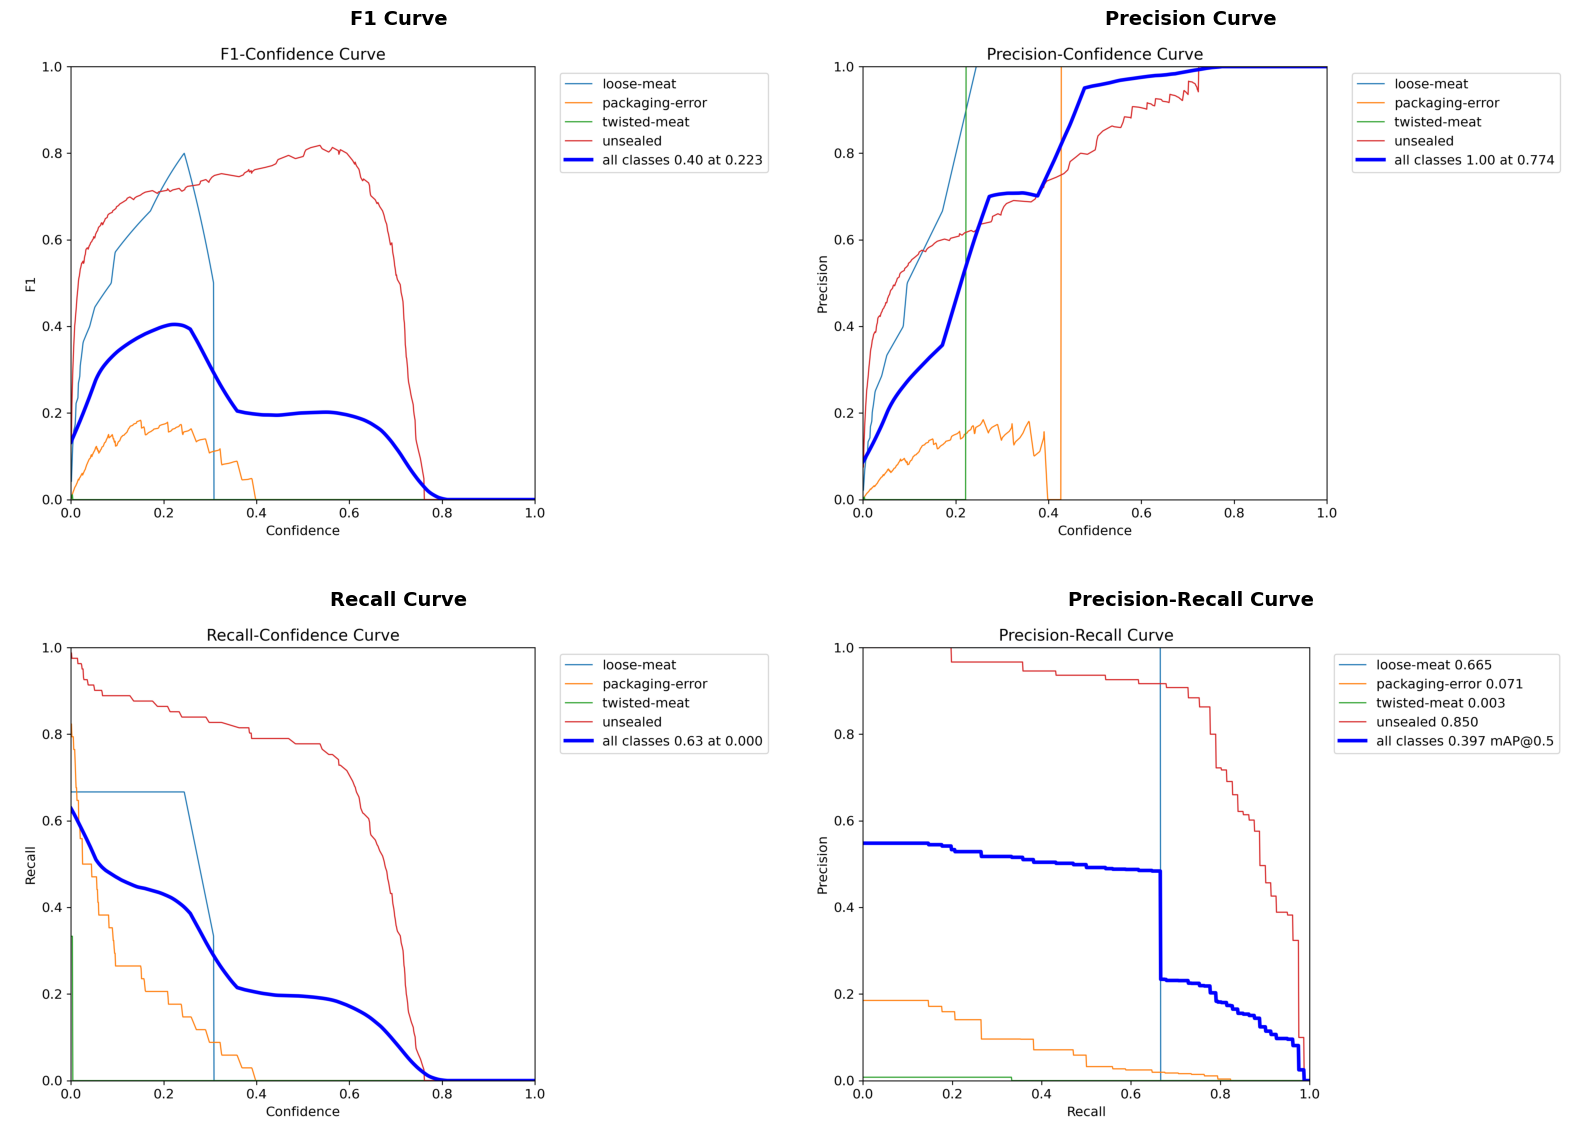

Evaluation plots saved to: /content/drive/MyDrive/YOLO26n Saved Weight/Trial 2 Evaluation-16


In [ ]:
"""Evaluate the saved Trial 2 model and display its performance curves.

Requires a mounted Google Drive containing the model weights and dataset.
Plots are loaded from the actual evaluation output directory.
"""

from pathlib import Path

import matplotlib.pyplot as plt
from google.colab import drive
from PIL import Image
from ultralytics import YOLO

WEIGHTS_PATH = "/content/drive/MyDrive/YOLO26n Saved Weight/Trial 3 Best Weight.pt"
DATA_PATH = "/content/drive/MyDrive/DATASET 3 - Pork Rasher/data.yaml"
OUTPUT_PROJECT = "/content/drive/MyDrive/YOLO26n Saved Weight"


def evaluate_and_plot(weights_path, data_path, project, image_size=1280, batch_size=4):
    """Evaluate validation data, display four curves, and return the model and metrics.

    Args:
        weights_path: Path to the saved YOLO checkpoint.
        data_path: Path to the dataset YAML configuration.
        project: Directory in which evaluation outputs are saved.
        image_size: Input image size used for evaluation.
        batch_size: Number of images evaluated per batch.

    Returns:
        A pair containing the loaded YOLO model and its validation metrics.
    """
    evaluated_model = YOLO(weights_path)
    evaluation = evaluated_model.val(
        data=data_path,
        split="val",
        imgsz=image_size,
        batch=batch_size,
        plots=True,
        project=project,
        name="Trial 2 Evaluation",
    )
    results_dir = Path(evaluation.save_dir)
    plot_files = [
        ("BoxF1_curve.png", "F1 Curve"),
        ("BoxP_curve.png", "Precision Curve"),
        ("BoxR_curve.png", "Recall Curve"),
        ("BoxPR_curve.png", "Precision-Recall Curve"),
    ]
    fig, axes = plt.subplots(2, 2, figsize=(16, 12))
    for ax, (filename, title) in zip(axes.flat, plot_files):
        filepath = results_dir / filename
        if filepath.is_file():
            with Image.open(filepath) as image:
                ax.imshow(image)
        else:
            ax.text(0.5, 0.5, f"{filename}\nNot found", ha="center", va="center")
        ax.set_title(title, fontsize=14, fontweight="bold")
        ax.axis("off")
    fig.tight_layout()
    plt.show()
    print("Evaluation plots saved to:", results_dir)
    return evaluated_model, evaluation


drive.mount("/content/drive")
model, metrics = evaluate_and_plot(WEIGHTS_PATH, DATA_PATH, OUTPUT_PROJECT)


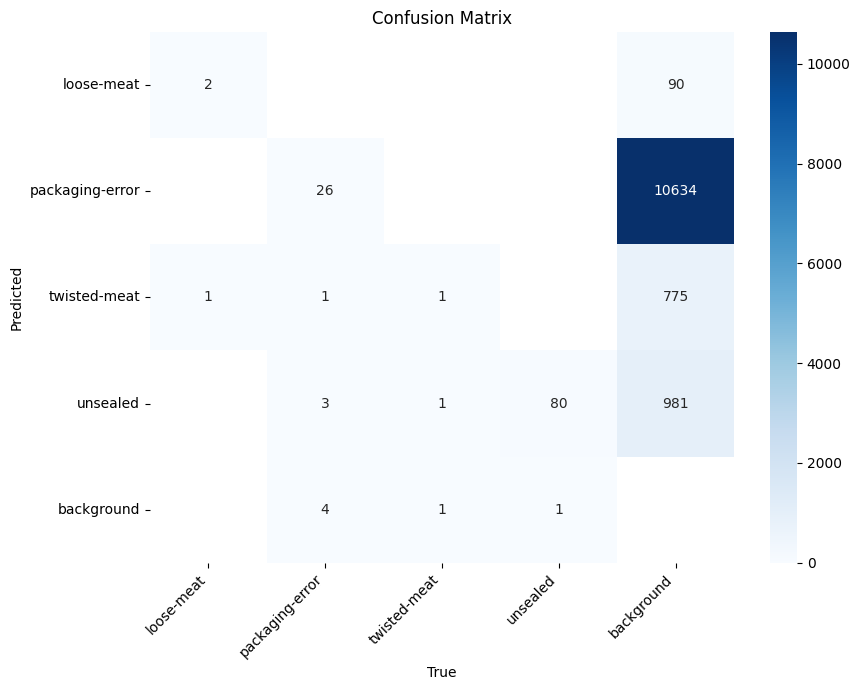

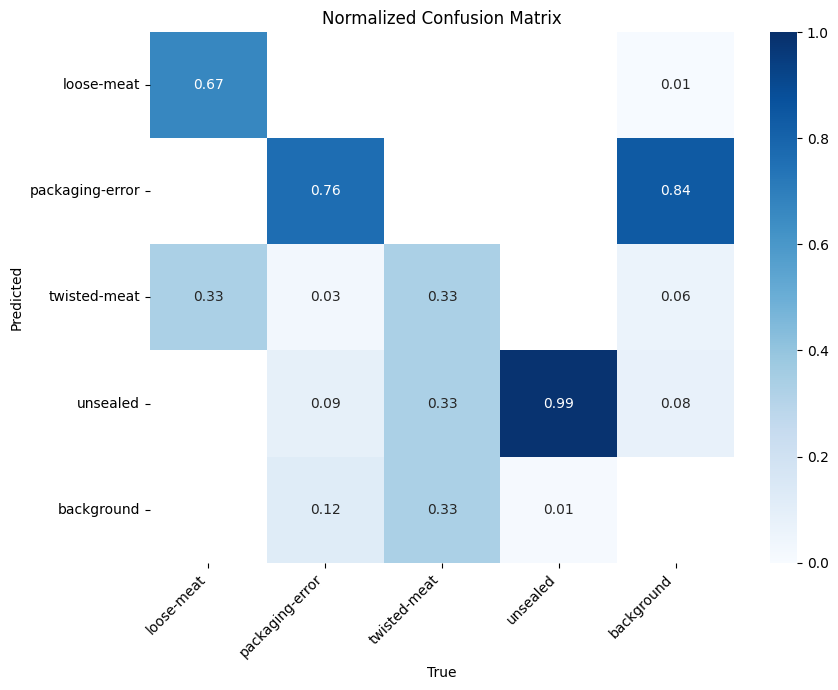

In [ ]:
"""Display and save confusion matrices.

Normalize the full matrix before filtering to preserve original percentages.
Run the evaluation cell first to create model and metrics.
"""

import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from pathlib import Path

cm = np.asarray(metrics.confusion_matrix.matrix).copy()
labels = [model.names[i] for i in range(len(model.names))]
labels += ["background"]

keep = [
    i for i, name in enumerate(labels)
    if name.strip().lower() != "wrinkle"
]
visible_labels = [labels[i] for i in keep]

# Preserve the original percentages before removing the row/column
totals = cm.sum(axis=0, keepdims=True)
normalized = np.divide(
    cm, totals,
    out=np.zeros_like(cm, dtype=float),
    where=totals != 0
)

for values, title, filename, fmt in [
    (cm.astype(int), "Confusion Matrix",
     "confusion_matrix_no_wrinkle.png", "d"),
    (normalized, "Normalized Confusion Matrix",
     "confusion_matrix_normalized_no_wrinkle.png", ".2f")
]:
    filtered = values[np.ix_(keep, keep)]

    fig, ax = plt.subplots(figsize=(9, 7))
    sns.heatmap(
        filtered, annot=True, fmt=fmt, cmap="Blues",
        mask=filtered == 0, vmin=0,
        vmax=1 if fmt == ".2f" else None,
        xticklabels=visible_labels,
        yticklabels=visible_labels,
        ax=ax
    )
    ax.set(title=title, xlabel="True", ylabel="Predicted")
    plt.xticks(rotation=45, ha="right")
    plt.yticks(rotation=0)
    plt.tight_layout()
    fig.savefig(
        Path(metrics.save_dir) / filename,
        dpi=200, bbox_inches="tight"
    )
    plt.show()

In [ ]:
"""Summarize the loaded YOLO model and measure its activations.

Run the evaluation cell first to load the saved model. This cell defines
network and creates its own activation table; no earlier profiling cell is
required. Counts describe the current loaded model, which may be fused or
frozen after evaluation. Gradient flags do not indicate training history.
"""

import pandas as pd
import torch
from IPython.display import display


def collect_layer_activations(network, image_size=640):
    """Return tensor output shapes and activation counts for leaf modules.

    Run one dummy image on the model's current device and dtype without
    gradients. Always remove hooks and restore module training modes,
    including if the forward pass fails. Counts include intermediate leaf
    outputs and are not a measurement of GPU memory traffic.
    """
    rows = []
    handles = []
    modes = [(module, module.training) for module in network.modules()]
    reference = next(network.parameters())

    def make_hook(name):
        """Create a hook that records tensor outputs for a named module."""
        def hook(module, inputs, output):
            """Record output shape and per-image tensor activation count."""
            if isinstance(output, torch.Tensor):
                rows.append({
                    "Layer": name,
                    "Type": type(module).__name__,
                    "Output Shape": tuple(output.shape),
                    "Activations": output.numel(),  # Dummy batch size is one.
                })
        return hook

    try:
        network.eval()
        for name, module in network.named_modules():
            if name and not list(module.children()):
                handles.append(module.register_forward_hook(make_hook(name)))
        dummy_input = torch.zeros(
            (1, 3, image_size, image_size),
            device=reference.device,
            dtype=reference.dtype,
        )
        with torch.no_grad():
            network(dummy_input)
    finally:
        for handle in handles:
            handle.remove()
        for module, was_training in modes:
            module.training = was_training

    return pd.DataFrame(rows, columns=[
        "Layer", "Type", "Output Shape", "Activations"
    ])


if "model" not in globals():
    raise RuntimeError("Run the evaluation cell first to load the saved YOLO model.")

network = model.model
df = collect_layer_activations(network, image_size=640)

total_params = sum(parameter.numel() for parameter in network.parameters())
tuned_params = sum(
    parameter.numel() for parameter in network.parameters()
    if parameter.requires_grad
)
total_layers = sum(1 for _ in network.modules())
total_neurons = sum(
    getattr(module, "out_channels", getattr(module, "out_features", 0))
    for module in network.modules()
)
total_activations = int(df["Activations"].sum())

display(df)
print("=" * 62)
print("YOLO26n LOADED MODEL SUMMARY")
print("=" * 62)
for label, value in [
    ("Modules (including containers)", total_layers),
    ("Output channels/features (sum)", total_neurons),
    ("Recorded activations (640x640)", total_activations),
    ("Total parameters", total_params),
    ("Parameters requiring gradients", tuned_params),
]:
    print(f"{label + ':':<42} {value:,}")
print("=" * 62)


In [ ]:
"""Estimate the model's FP32 roofline using Colab G4 GPU specifications.

Reference GPU: NVIDIA RTX PRO 6000 Blackwell Server Edition (one full GPU).
Use Google's G4 FP32 CUDA-core peak and NVIDIA's memory bandwidth:
https://docs.cloud.google.com/compute/docs/gpus
https://www.nvidia.com/en-us/data-center/rtx-pro-6000-blackwell-server-edition/

The FLOP count and activation count below describe the existing 640x640,
single-image model estimate. Activation reads/writes approximate memory
traffic; they do not measure GPU DRAM traffic or training performance.
The reference does not change the Colab runtime or require a connected GPU.
"""

# Existing model workload estimate: one 640x640 image, FP32 (4 bytes/value).
total_flops = 5.4e9
total_params = 2_535_830
total_activations = 63_685_600
bytes_per_param = 4
bytes_per_activation = 4

param_memory = total_params * bytes_per_param
activation_memory = total_activations * bytes_per_activation * 2
total_memory_accessed_bytes = param_memory + activation_memory
arithmetic_intensity = total_flops / total_memory_accessed_bytes

# Decimal SI units: 1 TFLOP/s = 10^12 FLOP/s; 1 GB/s = 10^9 bytes/s.
# Use FP32 CUDA-core throughput to match the FP32 workload assumption.
reference_gpu = "Colab G4 - NVIDIA RTX PRO 6000 Blackwell Server Edition"
peak_fp32_tflops = 117.0
memory_bandwidth_gb_s = 1597.0
peak_fp32_flops_s = peak_fp32_tflops * 1e12
memory_bandwidth_bytes_s = memory_bandwidth_gb_s * 1e9

# Roofline ridge point = peak compute throughput / peak memory bandwidth.
ridge_point = peak_fp32_flops_s / memory_bandwidth_bytes_s
bandwidth_roof_flops_s = arithmetic_intensity * memory_bandwidth_bytes_s
estimated_roofline_flops_s = min(peak_fp32_flops_s, bandwidth_roof_flops_s)
bound_type = (
    "MEMORY-BANDWIDTH-LIMITED" if arithmetic_intensity < ridge_point
    else "COMPUTE-LIMITED"
)

print("=" * 76)
print("ARITHMETIC INTENSITY AND G4 REFERENCE ROOFLINE (FP32 ESTIMATE)")
print("=" * 76)
print(f"Reference GPU:              {reference_gpu}")
print(f"Reference FP32 peak:        {peak_fp32_tflops:.1f} TFLOP/s")
print(f"Reference memory bandwidth: {memory_bandwidth_gb_s:.0f} GB/s")
print(f"Model FLOPs per image:      {total_flops / 1e9:.2f} GFLOPs")
print(f"Parameter memory:           {param_memory / 1024**2:.2f} MiB")
print(f"Activation read/write:      {activation_memory / 1024**2:.2f} MiB")
print(f"Estimated memory traffic:   {total_memory_accessed_bytes / 1024**2:.2f} MiB")
print(f"Arithmetic intensity:       {arithmetic_intensity:.4f} FLOPs/byte")
print(f"G4 reference ridge point:   {ridge_point:.2f} FLOPs/byte")
print(f"Idealized roofline ceiling: {estimated_roofline_flops_s / 1e12:.2f} TFLOP/s")
print("-" * 76)
print(f"Estimated regime under these assumptions: {bound_type}")
print("This is a theoretical FP32 reference, not measured GPU performance.")
print("The 640x640 workload estimate does not describe 1280x1280 training.")
print("=" * 76)


ARITHMETIC INTENSITY AND G4 REFERENCE ROOFLINE (FP32 ESTIMATE)
Reference GPU:              Colab G4 - NVIDIA RTX PRO 6000 Blackwell Server Edition
Reference FP32 peak:        117.0 TFLOP/s
Reference memory bandwidth: 1597 GB/s
Model FLOPs per image:      5.40 GFLOPs
Parameter memory:           9.67 MiB
Activation read/write:      485.88 MiB
Estimated memory traffic:   495.56 MiB
Arithmetic intensity:       10.3920 FLOPs/byte
G4 reference ridge point:   73.26 FLOPs/byte
Idealized roofline ceiling: 16.60 TFLOP/s
----------------------------------------------------------------------------
Estimated regime under these assumptions: MEMORY-BANDWIDTH-LIMITED
This is a theoretical FP32 reference, not measured GPU performance.
The 640x640 workload estimate does not describe 1280x1280 training.


In [ ]:
"""
Evaluate the YOLO model and report average detection time per image.
"""

metrics = model.val(
    data=DATA_PATH,
    split="val",
    imgsz=1280,
    batch=1,
    device=0,
    rect=False,
    augment=False,
    plots=False,
)

speed = metrics.speed
processing_ms = sum(
    speed[key] for key in ("preprocess", "inference", "postprocess")
)

print(f"Inference: {speed['inference']:.2f} ms/image")
print(f"Preprocessing + inference + postprocessing: {processing_ms:.2f} ms/image")

Ultralytics 8.4.188 🚀 Python-3.13.16 torch-2.11.0+cu130 CUDA:0 (Tesla T4, 14913MiB)
YOLO26n summary (fused): 121 layers, 2,390,707 parameters, 0 gradients, 5.4 GFLOPs
val: Fast image access ✅ (ping: 0.6±0.2 ms, read: 58.0±13.8 MB/s, size: 66.6 KB)
val: Scanning /content/drive/MyDrive/DATASET 3 - Pork Rasher/valid/labels.cache... 120 images, 14 backgrounds, 0 corrupt: 100% ━━━━━━━━━━━━ 120/120 26.5Mit/s 0.0s
                 Class     Images  Instances      Box(P          R      mAP50  mAP50-95): 100% ━━━━━━━━━━━━ 120/120 28.9it/s 4.2s
                   all        120        121      0.623      0.424      0.381      0.168
            loose-meat          3          3      0.617      0.667      0.555      0.278
       packaging-error         23         34      0.191      0.176      0.107     0.0294
          twisted-meat          3          3          1          0    0.00537    0.00137
              unsealed         81         81      0.686      0.852      0.856      0.363
Speed: 4.0ms p